*สภาพแวดล้อมการวิจัยนี้ขับเคลื่อนด้วย IPython notebooks ซึ่งช่วยให้สามารถวิเคราะห์ข้อมูลและตรวจสอบความถูกต้องทางสถิติได้อย่างครอบคลุม โดยเราจะสาธิตเทคนิคพื้นฐานบางส่วนที่นี่*

`เซลล์โค้ด เทียบกับ เซลล์ข้อความ (Code Cells vs. Text Cells)`
ดังที่คุณเห็น แต่ละเซลล์สามารถเป็นได้ทั้งโค้ดหรือข้อความ หากต้องการเลือกระหว่างสองประเภทนี้ ให้เลือกจากเมนูแบบเลื่อนลง 'Cell Type' ที่มุมซ้ายบน

เซลล์โค้ดจะถูกประมวลผลเมื่อคุณกดปุ่มเล่น (play) หรือกดปุ่มลัด shift-enter การประมวลผลเซลล์จะรันโค้ดทีละบรรทัดตามลำดับ และแสดงผลลัพธ์ของบรรทัดสุดท้ายไว้ด้านล่างเซลล์

In [1]:
from fontTools.misc.cython import returns

2 + 2

4

ในบางครั้งจะไม่มีผลลัพธ์แสดงออกมา เช่น ในกรณีที่เป็นการกำหนดค่าตัวแปร (assignment)

In [2]:
X = 2

โปรดจำไว้ว่าเฉพาะผลลัพธ์จากบรรทัดสุดท้ายเท่านั้นที่จะถูกแสดงออกมา

In [3]:
2 + 3
3 + 3

6

อย่างไรก็ตาม คุณสามารถสั่งแสดงผลบรรทัดใดก็ได้ที่ต้องการโดยใช้คำสั่ง `print`

In [4]:
print(2+2)
3 + 3

4


6

(หมายเหตุ: โค้ดในภาพใช้ไวยากรณ์ของ Python 2 ซึ่งเขียน print 2 + 2 โดยไม่มีวงเล็บ)

ขณะที่เซลล์กำลังประมวลผล สัญลักษณ์ `[*]` จะแสดงขึ้นทางด้านซ้าย หากเซลล์ใดยังไม่เคยถูกรันเลย จะแสดงเป็น `[ ]` และเมื่อเซลล์นั้นประมวลผลเสร็จแล้ว ตัวเลขจะปรากฏขึ้นเพื่อระบุลำดับที่เซลล์นั้นถูกรันระหว่างการทำงานของโน้ตบุ๊ก เช่น `[5]` ลองรันเซลล์ด้านล่างนี้และสังเกตการทำงานดู

In [5]:
# ใช้เวลาสักครู่เพื่อประมวลผลบางอย่าง
c = 0
for i in range(100000000):
    c = c + i
c


4999999950000000

*การนำเข้าไลบรารี (Importing Libraries)*

โดยส่วนใหญ่แล้ว คุณจะต้องการเรียกใช้ฟังก์ชันจากไลบรารีที่สร้างไว้ล่วงหน้า คุณไม่สามารถนำเข้าทุกไลบรารีบน Quantopian ได้เนื่องจากเหตุผลด้านความปลอดภัย แต่สามารถนำเข้าไลบรารีทางวิทยาศาสตร์ที่ใช้กันทั่วไปได้เกือบทั้งหมด ในที่นี้ฉันได้นำเข้า `numpy` และ `pandas` ซึ่งเป็นสองไลบรารีที่นิยมใช้และมีประโยชน์มากที่สุดในด้านการเงินเชิงปริมาณ (quant finance) ฉันขอแนะนำให้คัดลอกคำสั่ง import เหล่านี้ไปใส่ไว้ในทุกโน้ตบุ๊กใหม่ที่คุณสร้าง

โปรดสังเกตว่าคุณสามารถเปลี่ยนชื่อไลบรารีเป็นชื่ออะไรก็ได้ตามต้องการหลังจากนำเข้า โดยคำสั่ง `as` จะช่วยให้ทำสิ่งนี้ได้ ในที่นี้เราใช้ `np` และ `pd` เป็นชื่อย่อ `(aliases)` สำหรับ numpy และ pandas การตั้งชื่อย่อแบบนี้เป็นเรื่องปกติมากและพบได้ทั่วไปในตัวอย่างโค้ดตามเว็บไซต์ต่างๆ โดยมีจุดประสงค์เพื่อให้คุณพิมพ์ตัวอักษรน้อยลงเมื่อต้องเรียกใช้ไลบรารีเหล่านี้บ่อยๆ

In [6]:
import pandas as pd
import numpy as np


In [7]:
# นี่คือไลบรารีสำหรับพล็อตกราฟเพื่อให้ได้ภาพที่สวยงาม
import matplotlib.pyplot as plt

`สำหับ local ipynb , anaconda`
การกดปุ่ม `tab` จะแสดงรายการคำที่ IPython คาดเดาได้ดีที่สุดว่าคุณอาจจะพิมพ์ต่อไป ฟีเจอร์นี้มีประโยชน์อย่างยิ่งและจะช่วยประหยัดเวลาของคุณได้มาก หากมีตัวเลือกที่เป็นไปได้เพียงตัวเดียวสำหรับสิ่งที่คุณจะพิมพ์ต่อ **IPython** จะเติมคำนั้นให้คุณทันที ลองกดปุ่ม tab บ่อยๆ ดู เพราะระบบแทบจะไม่เติมคำที่คุณไม่ต้องการเลย เนื่องจากหากมีความคลุมเครือหรือมีหลายตัวเลือก ระบบจะแสดงรายการขึ้นมาให้เลือกแทน นี่เป็นวิธีที่ยอดเยี่ยมในการดูว่ามีฟังก์ชันอะไรให้ใช้งานบ้างภายในไลบรารีนั้นๆ

การใส่เครื่องหมายคำถาม (?) ไว้หลังชื่อฟังก์ชันแล้วรันโค้ดบรรทัดนั้น จะแสดงเอกสารคู่มือที่ IPython มีไว้สำหรับฟังก์ชันดังกล่าว โดยปกติแล้วควรทำในเซลล์ใหม่ เพื่อหลีกเลี่ยงการรันโค้ดส่วนอื่นซ้ำและป้องกันการเกิดข้อผิดพลาด (bugs)

In [8]:
np.random?

## การสุ่มตัวอย่างข้อมูล (Sampling)

เราจะทำการสุ่มตัวอย่างข้อมูลบางส่วนโดยใช้ฟังก์ชันจาก `numpy`

In [9]:
# สุ่มตัวอย่าง 100 จุด โดยมีค่าเฉลี่ย (mean) เท่ากับ 0 และส่วนเบี่ยงเบนมาตรฐาน (std) เท่ากับ 1 ซึ่งเป็นการแจกแจงปกติมาตรฐาน (standard normal distribution)
x = np.random.normal(0,1,100)

### การพล็อตกราฟ (Plotting)

เราสามารถใช้ไลบรารีสำหรับพล็อตกราฟที่เรานำเข้ามาแล้วได้ดังนี้

### การพล็อตกราฟ (Plotting)

เราสามารถใช้ไลบรารีสำหรับพล็อตกราฟที่เรานำเข้ามาแล้วได้ดังนี้

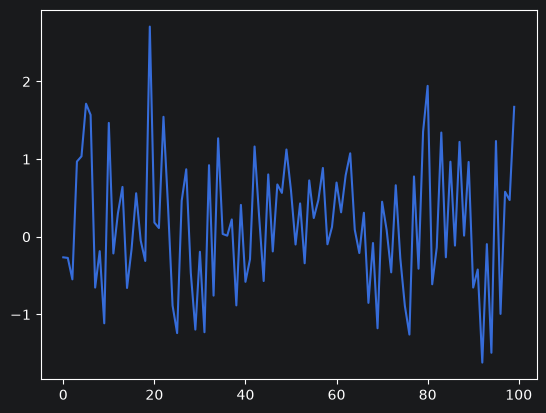

In [10]:
plt.plot(x)
plt.show()

#### การเพิ่มป้ายชื่อแกนกราฟ (Adding Axis Labels)
นักวิเคราะห์เชิงปริมาณ `(quant)` ที่มีความเป็นมืออาชีพจะไม่ปล่อยให้กราฟไม่มีป้ายชื่อกำกับแกนอย่างเด็ดขาด นี่คือคำสั่งบางส่วนที่จะช่วยจัดการเรื่องนั้น

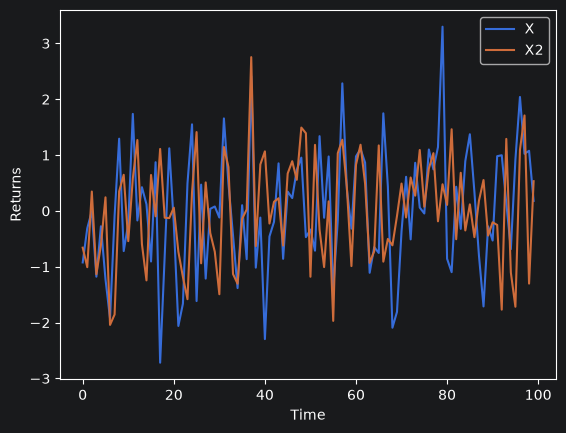

In [14]:
X = np.random.normal(0,1,100)
X2 = np.random.normal(0,1,100)

plt.plot(X);
plt.plot(X2);
plt.xlabel('Time');
plt.ylabel('Returns');
plt.legend(['X','X2']);
plt.show()
